In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [3]:
SEASONS = [
    "2021-22",
    "2022-23",
    "2023-24",
    "2024-25",
    "2025-26",
]

In [4]:
players = pd.read_csv("basketball_data/player_stats_five_seasons.csv")
players.head()

,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,AGE,GP,W,L,W_PCT,...,TS_PCT_RANK,USG_PCT_RANK,E_USG_PCT_RANK,E_PACE_RANK,PACE_RANK,sp_work_PACE_RANK,PIE_RANK,FGM_PG_RANK,FGA_PG_RANK,SEASON
0,203932,Aaron Gordon,Aaron,1610612743,DEN,26.0,75,46,29,0.613,...,124,200,211,354,463,463,218,81,106,2021-22
1,1630565,Aaron Henry,Aaron,1610612755,PHI,22.0,6,6,0,1.000,...,576,402,355,26,47,47,596,573,581,2021-22
2,1628988,Aaron Holiday,Aaron,1610612756,PHX,25.0,63,34,29,0.540,...,328,248,246,428,400,400,272,320,310,2021-22
3,1630174,Aaron Nesmith,Aaron,1610612738,BOS,22.0,52,32,20,0.615,...,435,324,316,318,312,312,510,440,434,2021-22
4,1630598,Aaron Wiggins,Aaron,1610612760,OKC,23.0,50,13,37,0.260,...,279,399,397,239,208,208,461,236,240,2021-22


In [5]:
df = pd.read_csv("basketball_data/play_type_pct.csv")

players = players.merge(
  df,
  on=["PLAYER_ID", "SEASON"],
  how="left",
)

In [6]:
players.head()

,PLAYER_ID,PLAYER_NAME,NICKNAME,TEAM_ID,TEAM_ABBREVIATION,AGE,GP,W,L,W_PCT,...,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT
0,203932,Aaron Gordon,Aaron,1610612743,DEN,26.0,75,46,29,0.613,...,0.040376,0.073239,0.058216,0.075117,0.015023,0.147418,0.047887,0.047887,0.175587,0.190610
1,1630565,Aaron Henry,Aaron,1610612755,PHI,22.0,6,6,0,1.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1628988,Aaron Holiday,Aaron,1610612756,PHX,25.0,63,34,29,0.540,...,0.040506,0.050633,0.065823,0.000000,0.000000,0.000000,0.387342,0.000000,0.301266,0.154430
3,1630174,Aaron Nesmith,Aaron,1610612738,BOS,22.0,52,32,20,0.615,...,0.000000,0.000000,0.058824,0.000000,0.101604,0.000000,0.000000,0.000000,0.641711,0.197861
4,1630598,Aaron Wiggins,Aaron,1610612760,OKC,23.0,50,13,37,0.260,...,0.024272,0.024272,0.036408,0.070388,0.000000,0.000000,0.111650,0.000000,0.402913,0.233010


In [7]:
features = [
    "USG_PCT",
    "AST_PCT",
    "SYNERGY_OFFENSIVE_CUT_PCT", 
    "SYNERGY_OFFENSIVE_HANDOFF_PCT",
    "SYNERGY_OFFENSIVE_ISOLATION_PCT",
    "SYNERGY_OFFENSIVE_MISC_PCT",
    "SYNERGY_OFFENSIVE_OFFREBOUND_PCT",
    "SYNERGY_OFFENSIVE_OFFSCREEN_PCT",
    "SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT",
    "SYNERGY_OFFENSIVE_PRROLLMAN_PCT",
    "SYNERGY_OFFENSIVE_POSTUP_PCT",
    "SYNERGY_OFFENSIVE_SPOTUP_PCT",
    "SYNERGY_OFFENSIVE_TRANSITION_PCT"
]

off_features = [
    col for col in features
    if col in players.columns
]

print("Available features:", off_features)

Available features: ['USG_PCT', 'AST_PCT', 'SYNERGY_OFFENSIVE_CUT_PCT', 'SYNERGY_OFFENSIVE_HANDOFF_PCT', 'SYNERGY_OFFENSIVE_ISOLATION_PCT', 'SYNERGY_OFFENSIVE_MISC_PCT', 'SYNERGY_OFFENSIVE_OFFREBOUND_PCT', 'SYNERGY_OFFENSIVE_OFFSCREEN_PCT', 'SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT', 'SYNERGY_OFFENSIVE_PRROLLMAN_PCT', 'SYNERGY_OFFENSIVE_POSTUP_PCT', 'SYNERGY_OFFENSIVE_SPOTUP_PCT', 'SYNERGY_OFFENSIVE_TRANSITION_PCT']


In [8]:
features_off = [
    "USG_PCT",
    "AST_PCT",
    "SYNERGY_OFFENSIVE_CUT_PCT", 
    "SYNERGY_OFFENSIVE_HANDOFF_PCT",
    "SYNERGY_OFFENSIVE_ISOLATION_PCT",
    "SYNERGY_OFFENSIVE_MISC_PCT",
    "SYNERGY_OFFENSIVE_OFFREBOUND_PCT",
    "SYNERGY_OFFENSIVE_OFFSCREEN_PCT",
    "SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT",
    "SYNERGY_OFFENSIVE_PRROLLMAN_PCT",
    "SYNERGY_OFFENSIVE_POSTUP_PCT",
    "SYNERGY_OFFENSIVE_SPOTUP_PCT",
    "SYNERGY_OFFENSIVE_TRANSITION_PCT",
    "SYNERGY_DEFENSIVE_CUT_PCT", 
    "SYNERGY_DEFENSIVE_HANDOFF_PCT",
    "SYNERGY_DEFENSIVE_ISOLATION_PCT",
    "SYNERGY_DEFENSIVE_MISC_PCT",
    "SYNERGY_DEFENSIVE_OFFREBOUND_PCT",
    "SYNERGY_DEFENSIVE_OFFSCREEN_PCT",
    "SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT",
    "SYNERGY_DEFENSIVE_PRROLLMAN_PCT",
    "SYNERGY_DEFENSIVE_POSTUP_PCT",
    "SYNERGY_DEFENSIVE_SPOTUP_PCT",
    "SYNERGY_DEFENSIVE_TRANSITION_PCT"
]

all_features = [
    col for col in features_off
    if col in players.columns
]

print("Available features:", all_features)

Available features: ['USG_PCT', 'AST_PCT', 'SYNERGY_OFFENSIVE_CUT_PCT', 'SYNERGY_OFFENSIVE_HANDOFF_PCT', 'SYNERGY_OFFENSIVE_ISOLATION_PCT', 'SYNERGY_OFFENSIVE_MISC_PCT', 'SYNERGY_OFFENSIVE_OFFREBOUND_PCT', 'SYNERGY_OFFENSIVE_OFFSCREEN_PCT', 'SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT', 'SYNERGY_OFFENSIVE_PRROLLMAN_PCT', 'SYNERGY_OFFENSIVE_POSTUP_PCT', 'SYNERGY_OFFENSIVE_SPOTUP_PCT', 'SYNERGY_OFFENSIVE_TRANSITION_PCT', 'SYNERGY_DEFENSIVE_HANDOFF_PCT', 'SYNERGY_DEFENSIVE_ISOLATION_PCT', 'SYNERGY_DEFENSIVE_OFFSCREEN_PCT', 'SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT', 'SYNERGY_DEFENSIVE_PRROLLMAN_PCT', 'SYNERGY_DEFENSIVE_POSTUP_PCT', 'SYNERGY_DEFENSIVE_SPOTUP_PCT']


In [9]:
features_def = [
    "USG_PCT",
    "AST_PCT",
    "SYNERGY_DEFENSIVE_CUT_PCT", 
    "SYNERGY_DEFENSIVE_HANDOFF_PCT",
    "SYNERGY_DEFENSIVE_ISOLATION_PCT",
    "SYNERGY_DEFENSIVE_MISC_PCT",
    "SYNERGY_DEFENSIVE_OFFREBOUND_PCT",
    "SYNERGY_DEFENSIVE_OFFSCREEN_PCT",
    "SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT",
    "SYNERGY_DEFENSIVE_PRROLLMAN_PCT",
    "SYNERGY_DEFENSIVE_POSTUP_PCT",
    "SYNERGY_DEFENSIVE_SPOTUP_PCT",
    "SYNERGY_DEFENSIVE_TRANSITION_PCT"
]

def_features = [
    col for col in features_def
    if col in players.columns
]

print("Available features:", def_features)

Available features: ['USG_PCT', 'AST_PCT', 'SYNERGY_DEFENSIVE_HANDOFF_PCT', 'SYNERGY_DEFENSIVE_ISOLATION_PCT', 'SYNERGY_DEFENSIVE_OFFSCREEN_PCT', 'SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT', 'SYNERGY_DEFENSIVE_PRROLLMAN_PCT', 'SYNERGY_DEFENSIVE_POSTUP_PCT', 'SYNERGY_DEFENSIVE_SPOTUP_PCT']


In [10]:
eligible = players[
    (players["GP"] >= 20) &
    (players["MIN"] >= 10)
].copy()

print("Total player-season rows:", len(players))
print("Eligible player-season rows:", len(eligible))

Total player-season rows: 2867
Eligible player-season rows: 2025


In [11]:
off_feature_data = eligible[off_features].copy()

off_feature_data = off_feature_data.replace(
    [np.inf, -np.inf],
    np.nan,
)
valid_mask = off_feature_data.notna().all(axis=1)

eligible = eligible.loc[valid_mask].copy()
off_feature_data = off_feature_data.loc[valid_mask].copy()

print("Rows available for clustering:", len(off_feature_data))
off_feature_data.head()

Rows available for clustering: 2017


,USG_PCT,AST_PCT,SYNERGY_OFFENSIVE_CUT_PCT,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT
0,0.194,0.109,0.128638,0.040376,0.073239,0.058216,0.075117,0.015023,0.047887,0.047887,0.147418,0.175587,0.190610
2,0.182,0.223,0.000000,0.040506,0.050633,0.065823,0.000000,0.000000,0.387342,0.000000,0.000000,0.301266,0.154430
3,0.164,0.057,0.000000,0.000000,0.000000,0.058824,0.000000,0.101604,0.000000,0.000000,0.000000,0.641711,0.197861
4,0.149,0.083,0.097087,0.024272,0.024272,0.036408,0.070388,0.000000,0.111650,0.000000,0.000000,0.402913,0.233010
7,0.143,0.084,0.080882,0.080882,0.000000,0.095588,0.000000,0.000000,0.000000,0.102941,0.000000,0.529412,0.110294


In [12]:
all_feature_data = eligible[all_features].copy()

all_feature_data = all_feature_data.replace(
    [np.inf, -np.inf],
    np.nan,
)
valid_mask = all_feature_data.notna().all(axis=1)

eligible = eligible.loc[valid_mask].copy()
all_feature_data = all_feature_data.loc[valid_mask].copy()

print("Rows available for clustering:", len(all_feature_data))
all_feature_data.head()

Rows available for clustering: 2017


,USG_PCT,AST_PCT,SYNERGY_OFFENSIVE_CUT_PCT,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT,SYNERGY_DEFENSIVE_HANDOFF_PCT,SYNERGY_DEFENSIVE_ISOLATION_PCT,SYNERGY_DEFENSIVE_OFFSCREEN_PCT,SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT,SYNERGY_DEFENSIVE_PRROLLMAN_PCT,SYNERGY_DEFENSIVE_POSTUP_PCT,SYNERGY_DEFENSIVE_SPOTUP_PCT
0,0.194,0.109,0.128638,0.040376,0.073239,0.058216,0.075117,0.015023,0.047887,0.047887,0.147418,0.175587,0.190610,0.082512,0.093596,0.071429,0.376847,0.036946,0.024631,0.314039
2,0.182,0.223,0.000000,0.040506,0.050633,0.065823,0.000000,0.000000,0.387342,0.000000,0.000000,0.301266,0.154430,0.107438,0.033058,0.057851,0.454545,0.044077,0.038567,0.264463
3,0.164,0.057,0.000000,0.000000,0.000000,0.058824,0.000000,0.101604,0.000000,0.000000,0.000000,0.641711,0.197861,0.083333,0.083333,0.095238,0.321429,0.000000,0.059524,0.357143
4,0.149,0.083,0.097087,0.024272,0.024272,0.036408,0.070388,0.000000,0.111650,0.000000,0.000000,0.402913,0.233010,0.079399,0.075107,0.092275,0.362661,0.000000,0.023605,0.366953
7,0.143,0.084,0.080882,0.080882,0.000000,0.095588,0.000000,0.000000,0.000000,0.102941,0.000000,0.529412,0.110294,0.000000,0.105769,0.000000,0.307692,0.000000,0.115385,0.471154


In [13]:
def_feature_data = eligible[def_features].copy()

def_feature_data = def_feature_data.replace(
    [np.inf, -np.inf],
    np.nan,
)
valid_mask = off_feature_data.notna().all(axis=1)

eligible = eligible.loc[valid_mask].copy()
def_feature_data = def_feature_data.loc[valid_mask].copy()

print("Rows available for clustering:", len(def_feature_data))
def_feature_data.head()

Rows available for clustering: 2017


,USG_PCT,AST_PCT,SYNERGY_DEFENSIVE_HANDOFF_PCT,SYNERGY_DEFENSIVE_ISOLATION_PCT,SYNERGY_DEFENSIVE_OFFSCREEN_PCT,SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT,SYNERGY_DEFENSIVE_PRROLLMAN_PCT,SYNERGY_DEFENSIVE_POSTUP_PCT,SYNERGY_DEFENSIVE_SPOTUP_PCT
0,0.194,0.109,0.082512,0.093596,0.071429,0.376847,0.036946,0.024631,0.314039
2,0.182,0.223,0.107438,0.033058,0.057851,0.454545,0.044077,0.038567,0.264463
3,0.164,0.057,0.083333,0.083333,0.095238,0.321429,0.000000,0.059524,0.357143
4,0.149,0.083,0.079399,0.075107,0.092275,0.362661,0.000000,0.023605,0.366953
7,0.143,0.084,0.000000,0.105769,0.000000,0.307692,0.000000,0.115385,0.471154


In [14]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(off_feature_data)

print("Feature matrix shape:", X_scaled.shape)

Feature matrix shape: (2017, 13)


In [15]:
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })

cluster_evaluation = pd.DataFrame(results)

display(cluster_evaluation)

,k,inertia,silhouette
0,2,19448.612462,0.299124
1,3,15468.881815,0.252568
2,4,13942.634393,0.226695
3,5,12654.813612,0.232719
4,6,11839.652930,0.198586
5,7,11289.721989,0.177098
6,8,10855.204968,0.162180
7,9,10517.010695,0.159518
8,10,10202.870543,0.160297


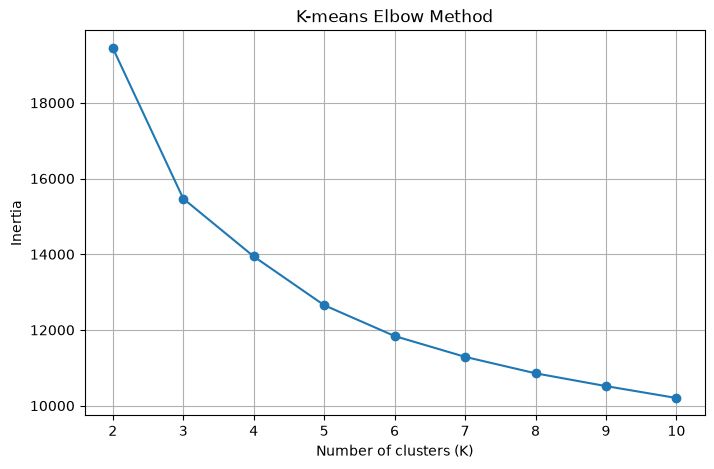

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["inertia"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-means Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

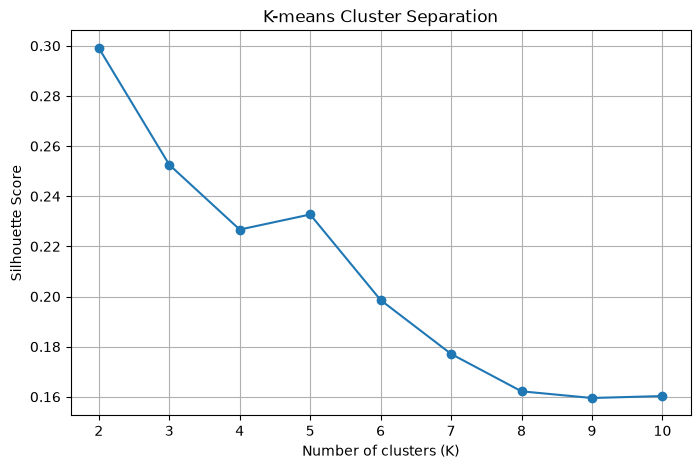

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["silhouette"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-means Cluster Separation")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [18]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20,
)

eligible["CLUSTER"] = kmeans.fit_predict(X_scaled)

cluster_profiles = eligible.groupby("CLUSTER")[off_features].mean()

display(cluster_profiles.round(3))

,USG_PCT,AST_PCT,SYNERGY_OFFENSIVE_CUT_PCT,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT
CLUSTER,,,,,,,,,,,,,
0,0.219,0.146,0.105,0.011,0.057,0.065,0.087,0.017,0.025,0.171,0.151,0.192,0.119
1,0.181,0.109,0.036,0.105,0.027,0.035,0.021,0.102,0.120,0.023,0.006,0.334,0.191
2,0.231,0.245,0.024,0.058,0.108,0.047,0.017,0.030,0.330,0.008,0.018,0.190,0.170
3,0.150,0.107,0.078,0.028,0.020,0.050,0.052,0.012,0.080,0.041,0.008,0.411,0.218
4,0.145,0.092,0.246,0.001,0.006,0.106,0.207,0.000,0.003,0.214,0.043,0.082,0.093


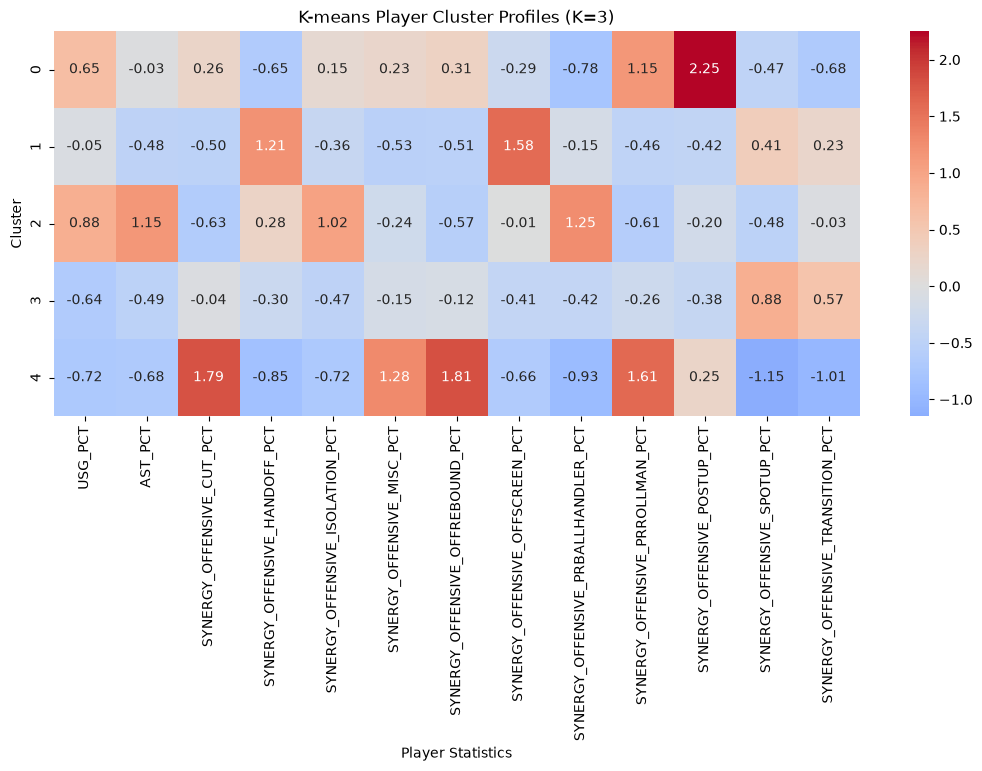

In [19]:
cluster_profiles_scaled = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=off_features,
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    cluster_profiles_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)

plt.title("K-means Player Cluster Profiles (K=3)")
plt.xlabel("Player Statistics")
plt.ylabel("Cluster")
plt.show()

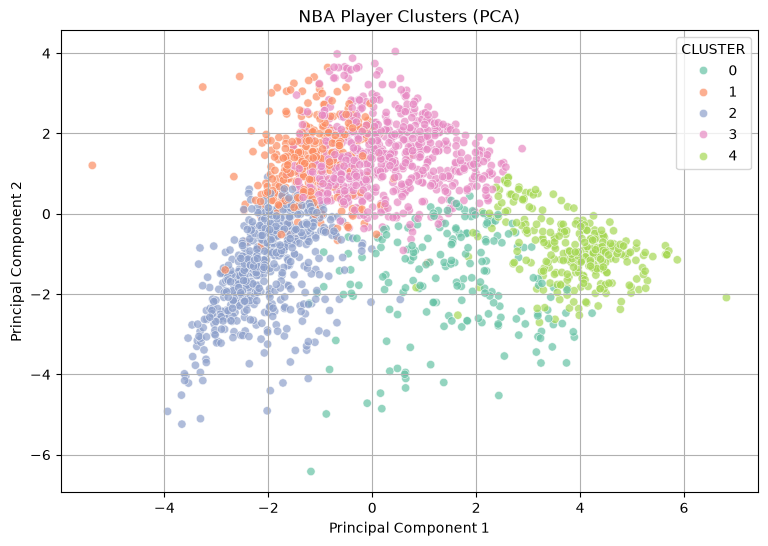

Variance explained by two components: 0.558


In [20]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

eligible["PC1"] = X_pca[:, 0]
eligible["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eligible,
    x="PC1",
    y="PC2",
    hue="CLUSTER",
    palette="Set2",
    alpha=0.7,
)

plt.title("NBA Player Clusters (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 3),
)

In [21]:
print("Cluster sizes:")
display(eligible["CLUSTER"].value_counts().sort_index())

Cluster sizes:


CLUSTER
0    190
1    324
2    581
3    639
4    283
Name: count, dtype: int64

In [22]:
eligible.to_csv(
    "basketball_data/cluster_off_play_type.csv",
    index=False,
)

print("Saved clustering results.")

Saved clustering results.


In [23]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(all_feature_data)

print("Feature matrix shape:", X_scaled.shape)

Feature matrix shape: (2017, 20)


In [24]:
results = []

for k in range(2, 15):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })

cluster_evaluation = pd.DataFrame(results)

display(cluster_evaluation)

,k,inertia,silhouette
0,2,31659.699256,0.285975
1,3,27619.801603,0.181769
2,4,25544.107948,0.192404
3,5,24001.678195,0.169250
4,6,23052.279580,0.144774
5,7,22187.454195,0.171182
6,8,21345.018419,0.143342
7,9,20722.243021,0.132037
8,10,20046.941220,0.136311
9,11,19669.579872,0.119261


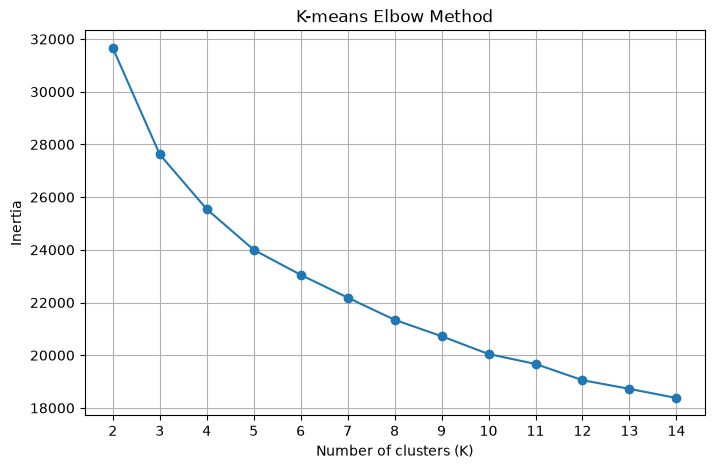

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["inertia"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-means Elbow Method")
plt.xticks(range(2, 15))
plt.grid(True)
plt.show()

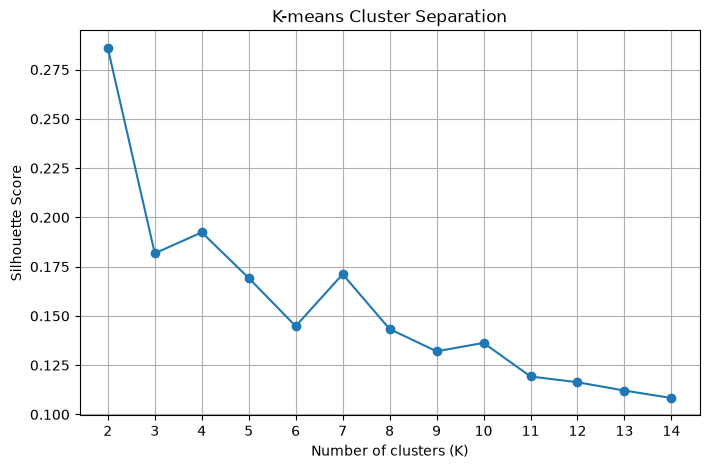

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["silhouette"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-means Cluster Separation")
plt.xticks(range(2, 15))
plt.grid(True)
plt.show()

In [27]:
kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=20,
)

eligible["CLUSTER"] = kmeans.fit_predict(X_scaled)

cluster_profiles = eligible.groupby("CLUSTER")[all_features].mean()

display(cluster_profiles.round(3))

,USG_PCT,AST_PCT,SYNERGY_OFFENSIVE_CUT_PCT,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT,SYNERGY_DEFENSIVE_HANDOFF_PCT,SYNERGY_DEFENSIVE_ISOLATION_PCT,SYNERGY_DEFENSIVE_OFFSCREEN_PCT,SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT,SYNERGY_DEFENSIVE_PRROLLMAN_PCT,SYNERGY_DEFENSIVE_POSTUP_PCT,SYNERGY_DEFENSIVE_SPOTUP_PCT
CLUSTER,,,,,,,,,,,,,,,,,,,,
0,0.181,0.109,0.035,0.106,0.027,0.035,0.021,0.101,0.120,0.022,0.006,0.333,0.193,0.084,0.092,0.066,0.318,0.029,0.041,0.371
1,0.150,0.106,0.077,0.029,0.021,0.050,0.052,0.012,0.080,0.036,0.009,0.414,0.220,0.074,0.098,0.056,0.338,0.034,0.047,0.351
2,0.229,0.243,0.023,0.058,0.106,0.046,0.016,0.030,0.333,0.007,0.015,0.196,0.170,0.081,0.076,0.054,0.346,0.034,0.048,0.353
3,0.162,0.097,0.201,0.003,0.007,0.092,0.180,0.001,0.005,0.226,0.075,0.122,0.087,0.015,0.209,0.015,0.035,0.136,0.148,0.442
4,0.242,0.172,0.086,0.017,0.096,0.055,0.071,0.027,0.052,0.121,0.163,0.173,0.139,0.033,0.114,0.034,0.334,0.089,0.053,0.334
5,0.152,0.107,0.224,0.001,0.009,0.104,0.176,0.002,0.004,0.204,0.044,0.120,0.110,0.007,0.089,0.010,0.556,0.084,0.041,0.208
6,0.202,0.212,0.076,0.088,0.102,0.073,0.043,0.029,0.334,0.018,0.018,0.141,0.078,0.331,0.210,0.182,0.000,0.110,0.156,0.011


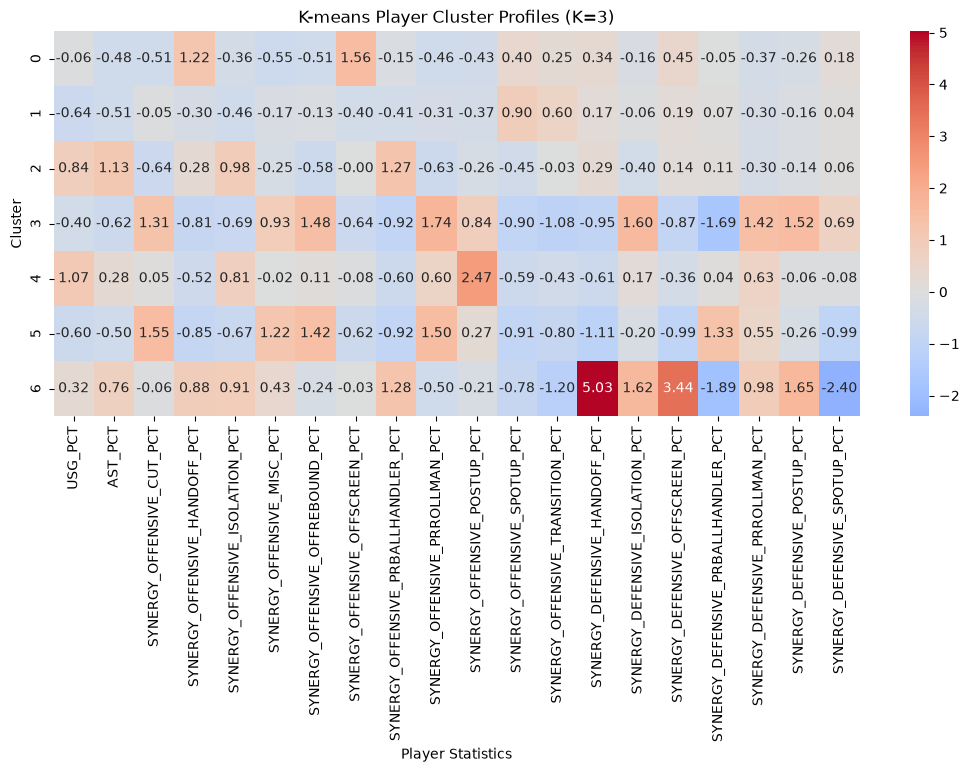

In [28]:
cluster_profiles_scaled = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=all_features,
)

plt.figure(figsize=(13, 5))

sns.heatmap(
    cluster_profiles_scaled,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)

plt.title("K-means Player Cluster Profiles (K=3)")
plt.xlabel("Player Statistics")
plt.ylabel("Cluster")
plt.show()

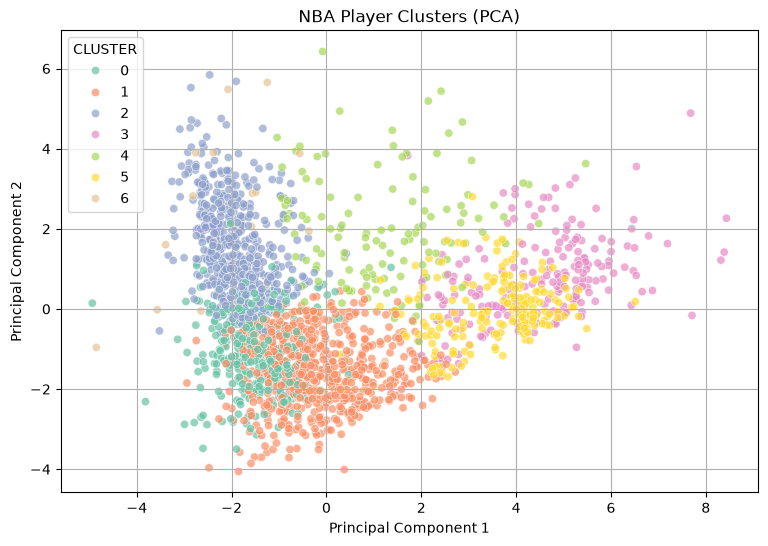

Variance explained by two components: 0.424


In [29]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

eligible["PC1"] = X_pca[:, 0]
eligible["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eligible,
    x="PC1",
    y="PC2",
    hue="CLUSTER",
    palette="Set2",
    alpha=0.7,
)

plt.title("NBA Player Clusters (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 3),
)

In [30]:
print("Cluster sizes:")
display(eligible["CLUSTER"].value_counts().sort_index())

Cluster sizes:


CLUSTER
0    321
1    615
2    555
3    189
4    124
5    194
6     19
Name: count, dtype: int64

In [31]:
eligible.to_csv(
    "basketball_data/cluster_all_play_type.csv",
    index=False,
)

print("Saved clustering results.")

Saved clustering results.


In [32]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20,
)

eligible["CLUSTER"] = kmeans.fit_predict(X_scaled)

cluster_profiles = eligible.groupby("CLUSTER")[all_features].mean()

display(cluster_profiles.round(3))

,USG_PCT,AST_PCT,SYNERGY_OFFENSIVE_CUT_PCT,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT,SYNERGY_DEFENSIVE_HANDOFF_PCT,SYNERGY_DEFENSIVE_ISOLATION_PCT,SYNERGY_DEFENSIVE_OFFSCREEN_PCT,SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT,SYNERGY_DEFENSIVE_PRROLLMAN_PCT,SYNERGY_DEFENSIVE_POSTUP_PCT,SYNERGY_DEFENSIVE_SPOTUP_PCT
CLUSTER,,,,,,,,,,,,,,,,,,,,
0,0.231,0.237,0.027,0.061,0.107,0.046,0.018,0.034,0.314,0.011,0.023,0.189,0.169,0.087,0.081,0.058,0.333,0.038,0.051,0.342
1,0.171,0.102,0.187,0.003,0.015,0.088,0.167,0.004,0.006,0.215,0.087,0.135,0.093,0.018,0.202,0.018,0.041,0.133,0.141,0.447
2,0.159,0.106,0.063,0.052,0.022,0.045,0.042,0.041,0.091,0.031,0.010,0.392,0.211,0.078,0.097,0.060,0.331,0.032,0.044,0.358
3,0.167,0.119,0.199,0.003,0.019,0.096,0.159,0.006,0.008,0.198,0.067,0.130,0.110,0.008,0.089,0.011,0.551,0.086,0.040,0.210


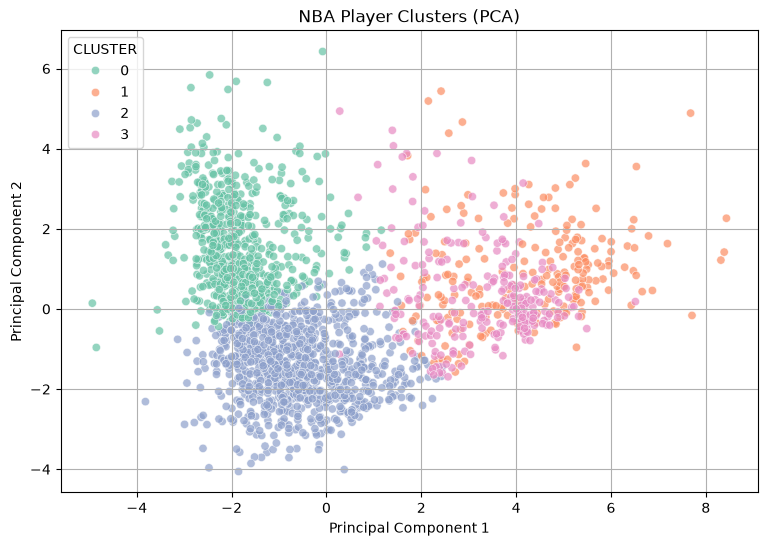

Variance explained by two components: 0.424


In [33]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

eligible["PC1"] = X_pca[:, 0]
eligible["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eligible,
    x="PC1",
    y="PC2",
    hue="CLUSTER",
    palette="Set2",
    alpha=0.7,
)

plt.title("NBA Player Clusters (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 3),
)

In [34]:
print("Cluster sizes:")
display(eligible["CLUSTER"].value_counts().sort_index())

Cluster sizes:


CLUSTER
0    638
1    222
2    915
3    242
Name: count, dtype: int64

In [35]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(def_feature_data)

print("Feature matrix shape:", X_scaled.shape)

Feature matrix shape: (2017, 9)


In [36]:
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })

cluster_evaluation = pd.DataFrame(results)

display(cluster_evaluation)

,k,inertia,silhouette
0,2,15192.941377,0.327874
1,3,13151.072739,0.198668
2,4,11642.060003,0.213559
3,5,10723.690077,0.219096
4,6,9953.406501,0.194534
5,7,9270.209139,0.200142
6,8,8877.628108,0.167886
7,9,8471.425242,0.179276
8,10,8128.174043,0.159101


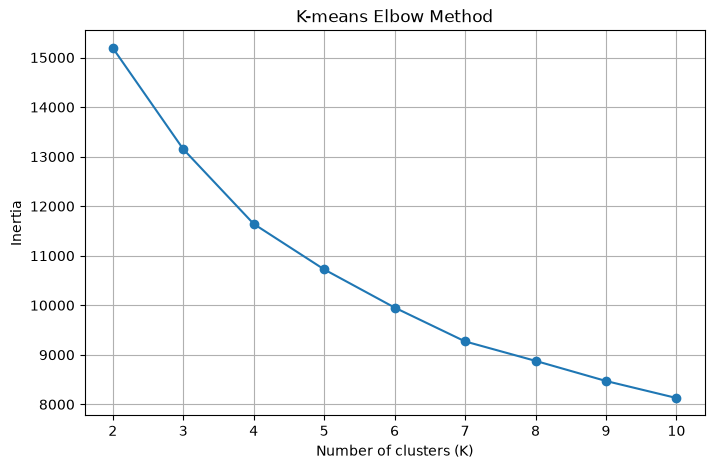

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["inertia"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("K-means Elbow Method")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

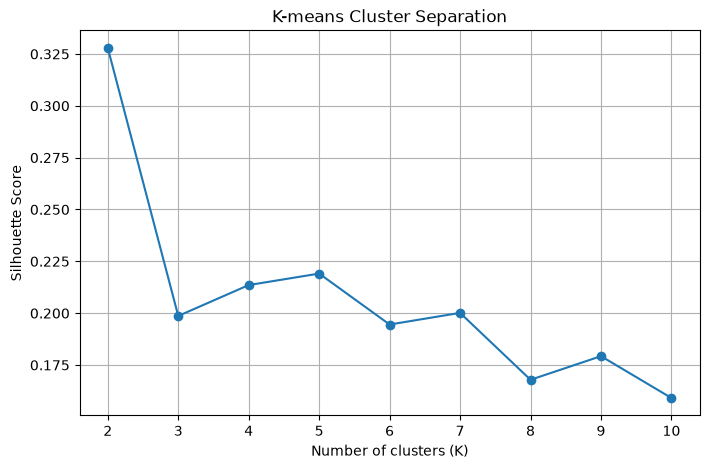

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_evaluation["k"],
    cluster_evaluation["silhouette"],
    marker="o",
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-means Cluster Separation")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [39]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20,
)

eligible["CLUSTER"] = kmeans.fit_predict(X_scaled)

cluster_profiles = eligible.groupby("CLUSTER")[all_features].mean()

display(cluster_profiles.round(3))

,USG_PCT,AST_PCT,SYNERGY_OFFENSIVE_CUT_PCT,SYNERGY_OFFENSIVE_HANDOFF_PCT,SYNERGY_OFFENSIVE_ISOLATION_PCT,SYNERGY_OFFENSIVE_MISC_PCT,SYNERGY_OFFENSIVE_OFFREBOUND_PCT,SYNERGY_OFFENSIVE_OFFSCREEN_PCT,SYNERGY_OFFENSIVE_PRBALLHANDLER_PCT,SYNERGY_OFFENSIVE_PRROLLMAN_PCT,SYNERGY_OFFENSIVE_POSTUP_PCT,SYNERGY_OFFENSIVE_SPOTUP_PCT,SYNERGY_OFFENSIVE_TRANSITION_PCT,SYNERGY_DEFENSIVE_HANDOFF_PCT,SYNERGY_DEFENSIVE_ISOLATION_PCT,SYNERGY_DEFENSIVE_OFFSCREEN_PCT,SYNERGY_DEFENSIVE_PRBALLHANDLER_PCT,SYNERGY_DEFENSIVE_PRROLLMAN_PCT,SYNERGY_DEFENSIVE_POSTUP_PCT,SYNERGY_DEFENSIVE_SPOTUP_PCT
CLUSTER,,,,,,,,,,,,,,,,,,,,
0,0.161,0.112,0.062,0.054,0.030,0.046,0.042,0.040,0.112,0.030,0.011,0.366,0.207,0.082,0.093,0.063,0.327,0.030,0.045,0.360
1,0.200,0.205,0.084,0.084,0.101,0.073,0.057,0.028,0.319,0.028,0.019,0.134,0.074,0.322,0.215,0.182,0.000,0.115,0.156,0.010
2,0.171,0.102,0.177,0.007,0.015,0.086,0.157,0.008,0.012,0.202,0.083,0.156,0.097,0.016,0.204,0.017,0.042,0.129,0.138,0.453
3,0.165,0.121,0.157,0.014,0.025,0.078,0.123,0.010,0.055,0.156,0.050,0.198,0.131,0.012,0.087,0.009,0.531,0.074,0.037,0.228
4,0.245,0.255,0.028,0.058,0.111,0.048,0.019,0.035,0.308,0.013,0.027,0.181,0.172,0.080,0.080,0.055,0.339,0.040,0.049,0.355


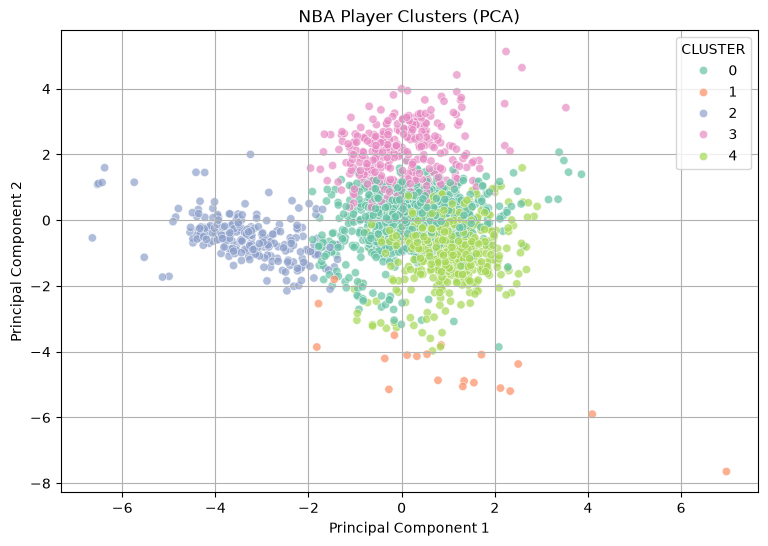

Variance explained by two components: 0.435


In [40]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

eligible["PC1"] = X_pca[:, 0]
eligible["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eligible,
    x="PC1",
    y="PC2",
    hue="CLUSTER",
    palette="Set2",
    alpha=0.7,
)

plt.title("NBA Player Clusters (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 3),
)

In [41]:
print("Cluster sizes:")
display(eligible["CLUSTER"].value_counts().sort_index())

Cluster sizes:


CLUSTER
0    953
1     20
2    230
3    315
4    499
Name: count, dtype: int64